# Profile: Dataset-P&ID (Digitize-PID)

What is in the 500 synthetic P&ID sheets and their answer keys, what is missing, how the values
are spread, and what a title block looks like. The findings feed Module C (P&ID reading).

| | |
|---|---|
| **What** | 500 synthetic P&ID sheets with annotations for 32 symbol types, text, lines and tables |
| **Source** | Google Drive folder `DigitizePID_Dataset`: https://drive.google.com/drive/folders/1gMm_YKBZtXB3qUKUpI-LF1HE_MgzwfeR (linked from the paper, arXiv 2109.03794) |
| **License** | The Drive folder has **no license file**; the paper only says the data is "made publicly available". The PID2Graph Zenodo record lists "Dataset PID" (its converted copy) as CC BY-SA 4.0 |
| **Citation** | Paliwal, S., Jain, A., Sharma, M., & Vig, L. (2021). Digitize-PID: Automatic Digitization of Piping and Instrumentation Diagrams. arXiv:2109.03794. https://doi.org/10.1007/978-3-030-75015-2_17 |

Copied from [`data/DATA_CATALOG.md`](../data/DATA_CATALOG.md). Spec:
[`specs/2026-10-16-profiling-notebooks/`](../specs/2026-10-16-profiling-notebooks/spec.md).

Run headless (inside the container, about two minutes):
`uv run --with jupyterlab jupyter nbconvert --to notebook --execute --inplace notebooks/00_profile_dataset_pid.ipynb`

**Safety and memory:** 4 of the 7 `.npy` types are object arrays that need *pickle* to load, and
pickle can run code. This notebook reads only their **header** (shape, type). Only the plain text
arrays (`KeyValue`, `Table`) are loaded, with `allow_pickle=False`. Image sizes come from the file
header; no image is decoded or shown.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.common import config
from src.datasets.profiling import image_sizes, npy_shapes

plt.rcParams.update({"figure.dpi": 72, "figure.figsize": (10, 3)})
pd.set_option("display.max_columns", 30, "display.width", 120)

DPID = config.RAW_DIR / "pid" / "dataset_pid"
KINDS = ["KeyValue", "Table", "lines", "lines2", "linker", "symbols", "words"]
shapes = npy_shapes(DPID)  # header only: about 1-2 minutes for 3,500 files
images = image_sizes(DPID / "image_2" / "image_2")
masks = image_sizes(DPID / "mask" / "mask")
images["drawing"] = images["file"].str.split(".").str[0].astype(int)
masks["drawing"] = masks["file"].str.split("_").str[0].astype(int)
drawing_dirs = sorted(int(p.name) for p in DPID.iterdir() if p.is_dir() and p.name.isdigit())

## 1. Counts

In [2]:
print(f"drawing folders: {len(drawing_dirs)} (numbers {drawing_dirs[0]}-{drawing_dirs[-1]})")
print(f".npy files: {len(shapes)}, images: {len(images)}, masks: {len(masks)}")
per_kind = shapes.groupby("kind").agg(
    files=("drawing", "size"),
    dtype=("dtype", lambda d: ", ".join(sorted(set(d)))),
    needs_pickle=("needs_pickle", "all"),
    total_rows=("rows", "sum"),
)
per_kind

drawing folders: 500 (numbers 0-499)
.npy files: 3500, images: 500, masks: 500


,files,dtype,needs_pickle,total_rows
kind,,,,
KeyValue,500,<U23,False,5000
Table,500,<U19,False,2514
lines,500,object,True,125267
lines2,500,int64,False,35074
linker,500,object,True,59498
symbols,500,object,True,59498
words,500,object,True,137967


## 2. Missing values

Every drawing should have all 7 `.npy` files, one image and one mask; an image and its mask
should have the same size.

In [3]:
present = shapes.pivot_table(index="drawing", columns="kind", values="rows", aggfunc="size")
present = present.reindex(index=drawing_dirs, columns=KINDS)
missing_npy = int(present.isna().sum().sum())
no_image = sorted(set(drawing_dirs) - set(images["drawing"]))
no_mask = sorted(set(drawing_dirs) - set(masks["drawing"]))
pairs = images.merge(masks, on="drawing", suffixes=("_image", "_mask"))
size_mismatch = pairs[
    (pairs["width_image"] != pairs["width_mask"]) | (pairs["height_image"] != pairs["height_mask"])
]
empty = shapes[shapes["rows"] == 0]
print(f"missing .npy files: {missing_npy}")
print(f"drawings without image: {len(no_image)}, without mask: {len(no_mask)}")
print(f"image/mask size mismatches: {len(size_mismatch)} of {len(pairs)} pairs")
print(f"empty arrays (0 rows): {len(empty)} {empty['kind'].value_counts().to_dict()}")

missing .npy files: 0
drawings without image: 0, without mask: 0
image/mask size mismatches: 0 of 500 pairs
empty arrays (0 rows): 0 {}


## 3. Distributions

Rows per drawing for each array type, read from the headers (e.g. `symbols` rows = symbols on the
sheet, `words` rows = text items), the image sizes, and the title-block fields.

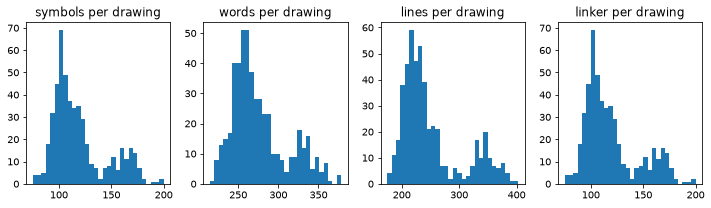

kind,KeyValue,Table,lines,lines2,linker,symbols,words
count,500.0,500.0,500.0,500.0,500.0,500.0,500.0
mean,10.0,5.0,250.5,70.1,119.0,119.0,275.9
std,0.0,0.8,52.7,5.6,25.7,25.7,34.3
min,10.0,4.0,175.0,68.0,75.0,75.0,215.0
25%,10.0,4.0,214.0,68.0,101.0,101.0,252.0
50%,10.0,5.0,232.0,68.0,111.0,111.0,266.0
75%,10.0,6.0,265.2,68.0,129.0,129.0,291.2
max,10.0,6.0,403.0,112.0,200.0,200.0,378.0


In [4]:
rows = shapes.pivot_table(index="drawing", columns="kind", values="rows", aggfunc="first")
fig, axes = plt.subplots(1, 4)
for ax, kind in zip(axes, ["symbols", "words", "lines", "linker"], strict=True):
    ax.hist(rows[kind], bins=30)
    ax.set_title(f"{kind} per drawing")
plt.tight_layout()
plt.show()
rows[KINDS].describe().round(1)

In [5]:
print("image sizes (width x height):")
print(
    (images["width"].astype(str) + " x " + images["height"].astype(str)).value_counts().to_string()
)

image sizes (width x height):
7168 x 4561    300
7168 x 4562    200


In [6]:
# Title blocks and revision tables are plain text arrays: loaded without pickle
key_values = pd.concat(
    [
        pd.DataFrame(
            np.load(DPID / str(n) / f"{n}_KeyValue.npy", allow_pickle=False),
            columns=["field", "value"],
        ).assign(drawing=n)
        for n in drawing_dirs
    ],
    ignore_index=True,
)
table_rows = rows["Table"] - 1  # first row is the header
field_counts = key_values["field"].value_counts()
print(
    f"title-block fields: {key_values['field'].nunique()} distinct names, "
    f"{rows['KeyValue'].min()}-{rows['KeyValue'].max()} per drawing"
)
print(f"revision table: {table_rows.min()}-{table_rows.max()} rows per drawing (header excluded)")
field_counts.rename("drawings").to_frame()

title-block fields: 10 distinct names, 10-10 per drawing
revision table: 3-5 rows per drawing (header excluded)


,drawings
field,
PROJECT/LOCATION/ASSIGN,500
ORGANIZATION,500
CONTRACTOR PROJECT NO.,500
CONTRACTOR NO.,500
DRAWING NAME,500
UNIT,500
CONTRACT NAME,500
SCALE,500
DRAW/SHEET NO.,500


## 4. Sample records

Title block and revision table of drawing 0. **The text is made up**: this is a synthetic
dataset. Source: Dataset-P&ID, Paliwal et al. 2021 (see the header).

In [7]:
key_values.loc[key_values["drawing"] == 0, ["field", "value"]]

,field,value
0,PROJECT/LOCATION/ASSIGN,IPY-65-37
1,ORGANIZATION,P-0
2,CONTRACTOR PROJECT NO.,AI-2148
3,CONTRACTOR NO.,847
4,DRAWING NAME,SAMPLE_7683.JPG
5,UNIT,39-6441
6,CONTRACT NAME,PROJ. XYZ P&ID
7,SCALE,None
8,DRAW/SHEET NO.,87623869
9,REV,2


In [8]:
table = np.load(DPID / "0" / "0_Table.npy", allow_pickle=False)
pd.DataFrame(table[1:], columns=table[0])

,ISSUE,DATE,MADE,CHECK'D,APPRV'D,DESCRIPTION
0,A,15/07/22,X.DD,NIA,Z.JDM,ISSUE CONSTR. REV.1
1,B,19Mar09,YWMJ,IT,SW,ISSUE CONSTR. REV.2
2,C,18May01,ZYD,E.TV,TNDT,ISSUE CONSTR. REV.3
3,D,24/07/08,YNO,A.AV,OEM,ISSUE CONSTR. REV.4


## 5. Findings

Every number below is computed from the tables above in this run.

In [9]:
pickled = per_kind.index[per_kind["needs_pickle"]].tolist()
sizes = images.groupby(["width", "height"]).size()
findings = [
    f"{len(drawing_dirs)} drawings, {len(shapes)} .npy files, {len(images)} images and "
    f"{len(masks)} masks; {missing_npy} .npy files, {len(no_image)} images and {len(no_mask)} "
    "masks are missing.",
    f"{len(pickled)} of {len(KINDS)} array types need pickle to load ({', '.join(pickled)}); "
    "these hold the symbols, text and pipes Module C needs. Loading them safely is a Phase 7 "
    "decision; this notebook only read their headers.",
    f"A sheet has {rows['symbols'].median():.0f} symbols and {rows['words'].median():.0f} "
    f"text items at the median (symbols {rows['symbols'].min()}-{rows['symbols'].max()}): "
    "dense drawings: detection must handle many objects per sheet.",
    f"linker has as many rows as symbols in {int((rows['linker'] == rows['symbols']).sum())} "
    f"of {len(rows)} drawings (header counts only; that each row links one symbol is not "
    "checked without loading the pickled data).",
    f"Images come in {len(sizes)} size(s), the most common "
    f"{sizes.idxmax()[0]} x {sizes.idxmax()[1]} px ({sizes.max()} images); "
    f"{len(size_mismatch)} image/mask size mismatches. Sheets this large must be tiled for a "
    "detector.",
    f"Title blocks have {rows['KeyValue'].min()}-{rows['KeyValue'].max()} fields "
    f"({key_values['field'].nunique()} distinct field names) and the revision table has "
    f"{table_rows.min()}-{table_rows.max()} rows: a clean, fixed layout that suits a "
    "title-block extraction demo, but the values are made up.",
]
for i, text in enumerate(findings, 1):
    print(f"{i}. {text}")

1. 500 drawings, 3500 .npy files, 500 images and 500 masks; 0 .npy files, 0 images and 0 masks are missing.
2. 4 of 7 array types need pickle to load (lines, linker, symbols, words); these hold the symbols, text and pipes Module C needs. Loading them safely is a Phase 7 decision; this notebook only read their headers.
3. A sheet has 111 symbols and 266 text items at the median (symbols 75-200): dense drawings: detection must handle many objects per sheet.
4. linker has as many rows as symbols in 500 of 500 drawings (header counts only; that each row links one symbol is not checked without loading the pickled data).
5. Images come in 2 size(s), the most common 7168 x 4561 px (300 images); 0 image/mask size mismatches. Sheets this large must be tiled for a detector.
6. Title blocks have 10-10 fields (10 distinct field names) and the revision table has 3-5 rows: a clean, fixed layout that suits a title-block extraction demo, but the values are made up.
